In [ ]:
!unzip archive.zip

Archive:  archive.zip
  inflating: netflix_titles.csv      


In [ ]:
!ls

archive.zip  netflix_titles.csv  sample_data


In [ ]:
import pandas as pd
df = pd.read_csv("netflix_titles.csv")
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [ ]:
df.shape

(8807, 12)

In [ ]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='object')

In [ ]:
df.isnull().sum()


,0
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df['director'] = df['director'].fillna('Unknown')
df['cast'] = df['cast'].fillna('Unknown')
df['country'] = df['country'].fillna('Unknown')

In [ ]:
df = df.dropna(subset=['date_added', 'rating', 'duration'])

In [ ]:
df['date_added'] = pd.to_datetime(df['date_added'].str.strip())
df['year_added'] = df['date_added'].dt.year

In [ ]:
df['date_added'] = pd.to_datetime(df['date_added'].str.strip())
df['year_added'] = df['date_added'].dt.year

AttributeError: Can only use .str accessor with string values!

In [ ]:
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,0
release_year,0
rating,0
duration,0


In [ ]:
df.to_csv('netflix_cleaned.csv', index=False)

In [ ]:
df['date_added'] = pd.to_datetime(df['date_added'].str.strip())
df['year_added'] = df['date_added'].dt.year



In [ ]:
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,0
release_year,0
rating,0
duration,0


In [ ]:
df.to_csv('netflix_cleaned.csv', index=False)

In [ ]:
df.to_csv('netflix_cleaned.csv', index=False)

In [ ]:
df.to_csv('netflix_cleaned.csv', index=False)

In [ ]:
df['type'].value_counts()

NameError: name 'df' is not defined

In [ ]:
import matplotlib.pyplot as plt

df['type'].value_counts().plot(kind='bar')
plt.title('Movies vs TV Shows on Netflix')
plt.xlabel('Type')
plt.ylabel('Number of titles')
plt.show()

NameError: name 'df' is not defined

In [ ]:
!unzip -o archive.zip

Archive:  archive.zip
  inflating: netflix_titles.csv      


In [ ]:
import pandas as pd

# Load the data
df = pd.read_csv("netflix_titles.csv")

# Fill the columns with many missing values
df['director'] = df['director'].fillna('Unknown')
df['cast'] = df['cast'].fillna('Unknown')
df['country'] = df['country'].fillna('Unknown')

# Remove rows with very few missing values
df = df.dropna(subset=['date_added', 'rating', 'duration'])

# Fix the date and make a year column
df['date_added'] = pd.to_datetime(df['date_added'].str.strip())
df['year_added'] = df['date_added'].dt.year

# Save the clean file
df.to_csv('netflix_cleaned.csv', index=False)

df.isnull().sum()

,0
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,0
release_year,0
rating,0
duration,0


In [ ]:
df['listed_in'].str.split(', ').explode().head(10)

,listed_in
0,Documentaries
1,International TV Shows
1,TV Dramas
1,TV Mysteries
2,Crime TV Shows
2,International TV Shows
2,TV Action & Adventure
3,Docuseries
3,Reality TV
4,International TV Shows


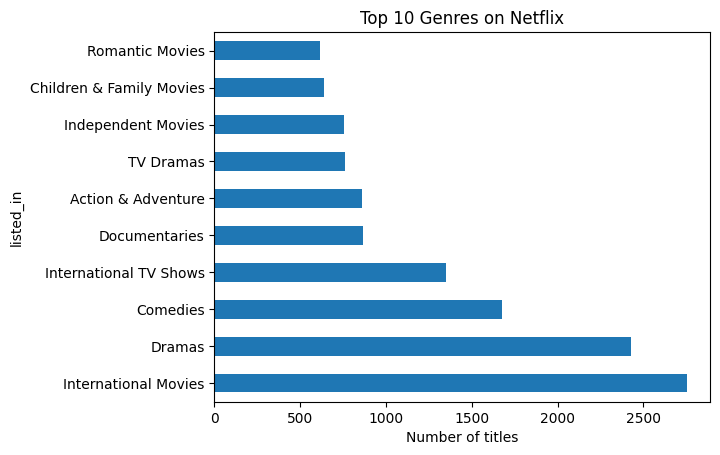

In [ ]:
genres = df['listed_in'].str.split(', ').explode()
genres.value_counts().head(10).plot(kind='barh')
plt.title('Top 10 Genres on Netflix')
plt.xlabel('Number of titles')
plt.show()

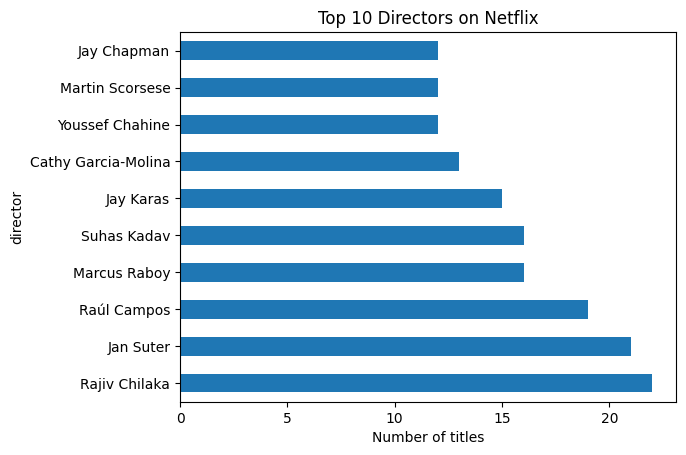

In [ ]:
directors = df[df['director'] != 'Unknown']['director'].str.split(', ').explode()
directors.value_counts().head(10).plot(kind='barh')
plt.title('Top 10 Directors on Netflix')
plt.xlabel('Number of titles')
plt.show()

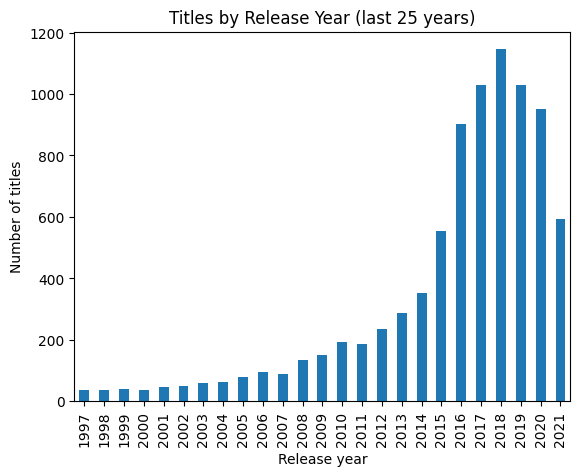

In [ ]:
df['release_year'].value_counts().sort_index().tail(25).plot(kind='bar')
plt.title('Titles by Release Year (last 25 years)')
plt.xlabel('Release year')
plt.ylabel('Number of titles')
plt.show()

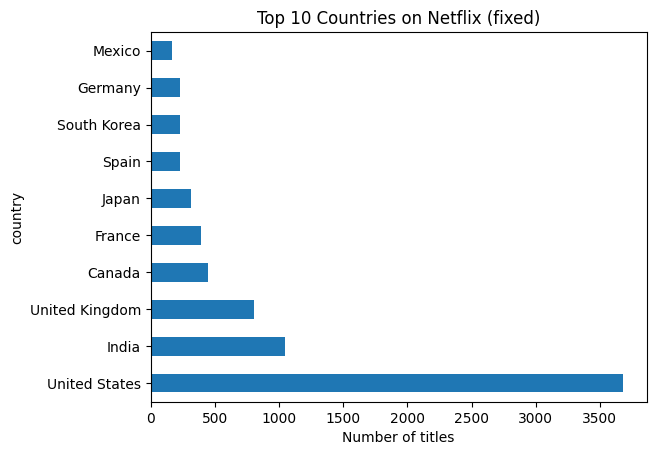

In [ ]:
countries = df[df['country'] != 'Unknown']['country'].str.split(', ').explode()
countries.value_counts().head(10).plot(kind='barh')
plt.title('Top 10 Countries on Netflix (fixed)')
plt.xlabel('Number of titles')
plt.show()

In [ ]:
genres = df[['show_id', 'listed_in']].copy()
genres['genre'] = genres['listed_in'].str.split(', ')
genres = genres.explode('genre')[['show_id', 'genre']]
genres.to_csv('netflix_genres.csv', index=False)

countries = df[df['country'] != 'Unknown'][['show_id', 'country']].copy()
countries['country'] = countries['country'].str.split(', ')
countries = countries.explode('country')
countries.to_csv('netflix_countries.csv', index=False)

In [ ]:
from google.colab import files
files.download('netflix_cleaned.csv')
files.download('netflix_genres.csv')
files.download('netflix_countries.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!unzip -o archive.zip

import pandas as pd

# Load the data
df = pd.read_csv("netflix_titles.csv")

# Clean the data
df['director'] = df['director'].fillna('Unknown')
df['cast'] = df['cast'].fillna('Unknown')
df['country'] = df['country'].fillna('Unknown')
df = df.dropna(subset=['date_added', 'rating', 'duration'])
df['date_added'] = pd.to_datetime(df['date_added'].str.strip())
df['year_added'] = df['date_added'].dt.year
df.to_csv('netflix_cleaned.csv', index=False)

# Make the genres file
genres = df[['show_id', 'listed_in']].copy()
genres['genre'] = genres['listed_in'].str.split(', ')
genres = genres.explode('genre')[['show_id', 'genre']]
genres.to_csv('netflix_genres.csv', index=False)

# Make the countries file
countries = df[df['country'] != 'Unknown'][['show_id', 'country']].copy()
countries['country'] = countries['country'].str.split(', ')
countries = countries.explode('country')
countries.to_csv('netflix_countries.csv', index=False)

# Download all 3 files
from google.colab import files
files.download('netflix_cleaned.csv')
files.download('netflix_genres.csv')
files.download('netflix_countries.csv')

Archive:  archive.zip
  inflating: netflix_titles.csv      


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>